In [2]:
%pip install -q \
    pillow \
    numpy \
    pandas \
    scipy \
    scikit-image \
    matplotlib \
    pydicom \
    SimpleITK

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
from PIL import Image
from glob import glob
import pandas as pd
import skimage, os
from skimage.morphology import ball, disk, dilation, binary_erosion, remove_small_objects, erosion, closing, reconstruction, binary_closing
from skimage.measure import label,regionprops, perimeter
from skimage.morphology import binary_dilation, binary_opening, convex_hull_image
from skimage.filters import roberts, sobel
from skimage import measure, feature
from skimage.segmentation import clear_border
from skimage import data
from scipy import ndimage as ndi
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
import pydicom
#import scipy.misc
import numpy as np
import SimpleITK as sitk

In [4]:
def load_itk(filename):
    # Reads the image using SimpleITK
    itkimage = sitk.ReadImage(filename)

    # Convert the image to a  numpy array first and then shuffle the dimensions to get axis in the order z,y,x
    image_array = sitk.GetArrayFromImage(itkimage)

    # Read the origin of the ct_scan, will be used to convert the coordinates from world to voxel and vice versa.
    origin = np.array(list(reversed(itkimage.GetOrigin())))

    # Read the spacing along each dimension
    spacing = np.array(list(reversed(itkimage.GetSpacing())))

    return image_array, origin, spacing

In [5]:
#luna_subset0_path = '../data/preprocessing/train/subset0/'
#luna_subset1_path = '../data/preprocessing/train/subset1/'
#luna_subset2_path = '../data/preprocessing/train/subset2/'

#file_list=glob(luna_subset0_path+"*.mhd") + glob(luna_subset1_path+"*.mhd") + glob(luna_subset2_path+"*.mhd")

def mhd_list(path):
    return glob(os.path.join(path, "*.mhd"))

file_list = (
    mhd_list("../data/preprocessing/train/subset0/")
    + mhd_list("../data/preprocessing/train/subset1/")
    + mhd_list("../data/preprocessing/train/subset2/")
)

print(f" {len(file_list)} fichiers CT trouvés")

 267 fichiers CT trouvés


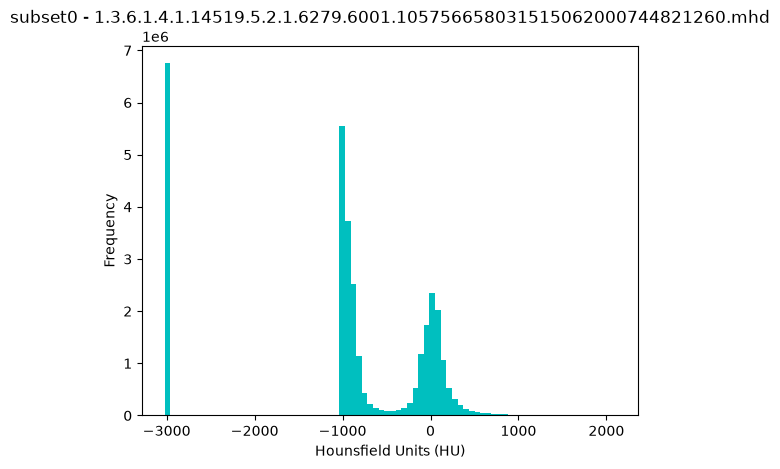

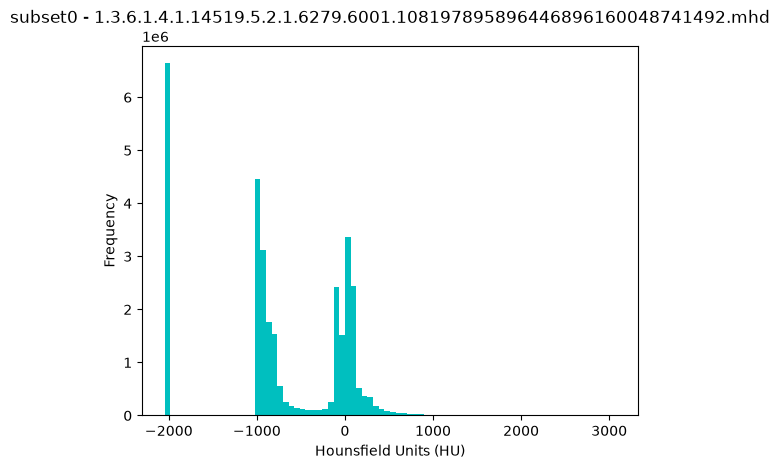

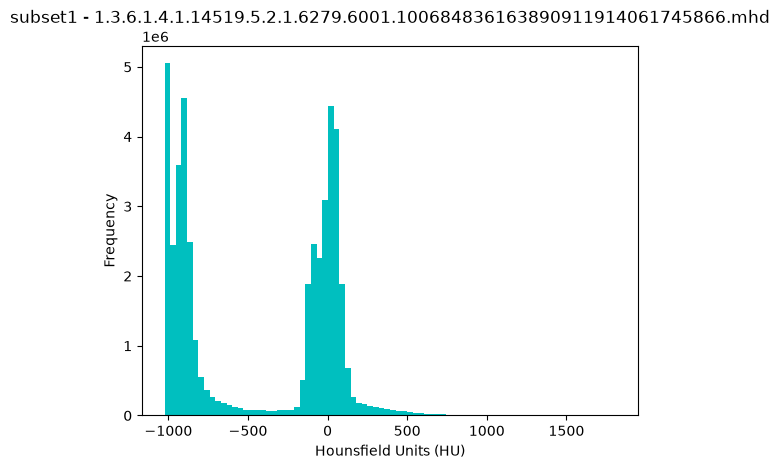

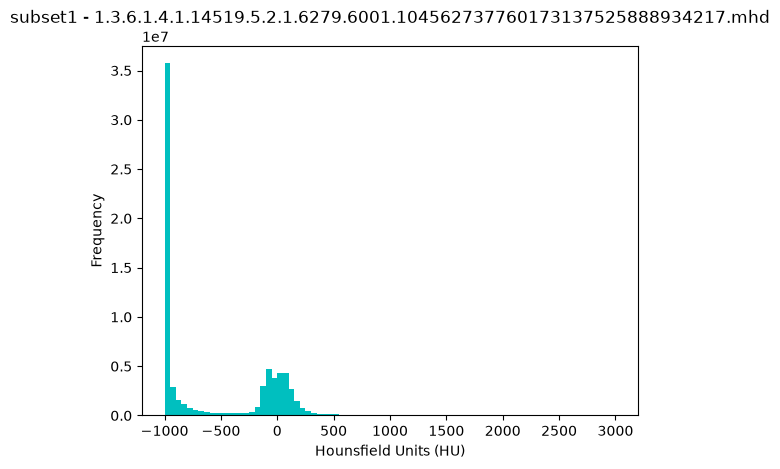

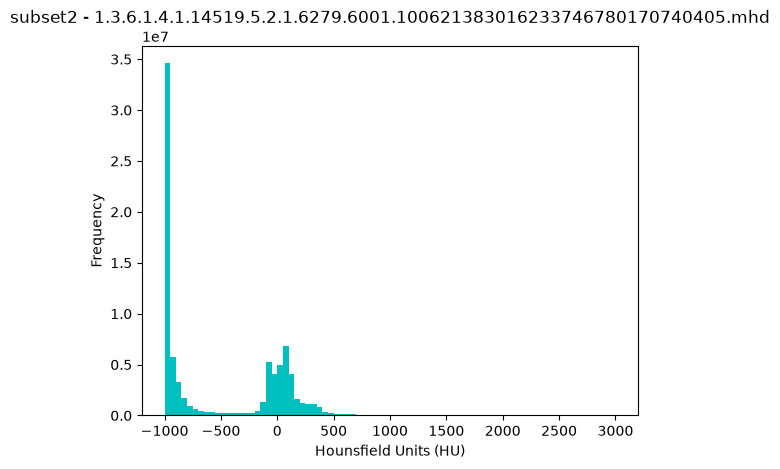

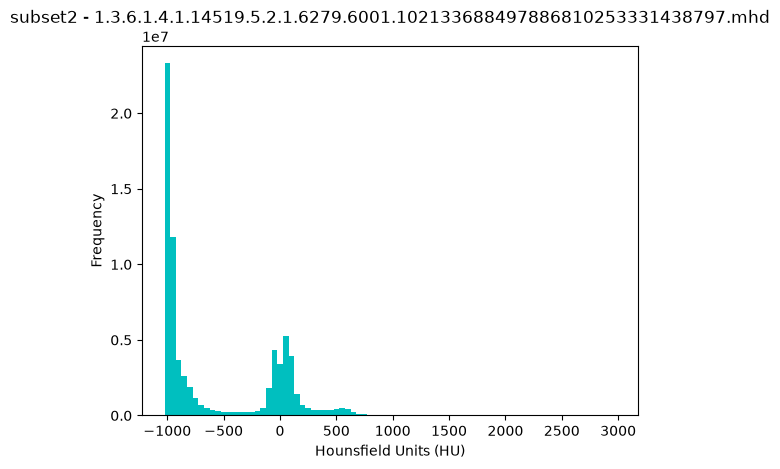

In [6]:
from collections import defaultdict
from matplotlib import pyplot as plt
import os

subset_files = defaultdict(list)

for f in file_list:
    subset_name = os.path.basename(os.path.dirname(f))
    subset_files[subset_name].append(f)



for subset_name, files in subset_files.items():
    for f in files[:2]:  # 2 patients par subset
        image_array, origin, spacing = load_itk(f)
        #plt.imshow(image_array[image_array.shape[0]//2], cmap='gray')
        plt.title(f"{subset_name} - {os.path.basename(f)}")
        plt.hist(image_array.flatten(), bins=80, color='c')
        plt.xlabel("Hounsfield Units (HU)")
        plt.ylabel("Frequency")
        #plt.axis("off")
        plt.show()
        



In [8]:
import numpy as np
import scipy.ndimage as ndi
from matplotlib import pyplot as plt

def resample(image, previous_spacing, new_spacing=[1,1,1]):
    # Determine current pixel spacing
    spacing = np.array(previous_spacing, dtype=np.float32)
    resize_factor = spacing / new_spacing
    new_real_shape = image.shape * resize_factor
    new_shape = np.round(new_real_shape)
    real_resize_factor = new_shape / image.shape
    new_spacing = spacing / real_resize_factor
    
    image = ndi.zoom(image, real_resize_factor, mode='nearest')
    
    return image, new_spacing


image_array, origin, spacing = load_itk(file_list[0])


img2, spacing2 = resample(image_array, spacing)

print("Original shape:", image_array.shape)
print("New shape:     ", img2.shape)
print("Original spacing:", spacing)
print("New spacing:     ", spacing2)

Original shape: (121, 512, 512)
New shape:      (302, 390, 390)
Original spacing: [2.5        0.76171899 0.76171899]
New spacing:      [1.00165563 1.00000031 1.00000031]


In [9]:
def get_segmented_lungs(im, plot=False):
    '''
    This funtion segments the lungs from the given 2D slice.
    '''
    plt_number = 0
    # Original image label: 0
    if plot:
        f, plots = plt.subplots(12, 1, figsize=(5, 40))
        plots[plt_number].axis('off')
        plots[plt_number].set_title(f'{plt_number}')
        plots[plt_number].imshow(im, cmap=plt.cm.bone)
        plt_number += 1

    # Step 1: Convert into a binary image.
    # image label: 1
    binary = im < -604
    if plot:
        plots[plt_number].axis('off')
        plots[plt_number].set_title(f'{plt_number}')
        plots[plt_number].imshow(binary, cmap=plt.cm.bone)
        plt_number += 1
    # Step 2: Remove the blobs connected to the border of the image.
    # image label: 2
    cleared = clear_border(binary)
    if plot:
        plots[plt_number].axis('off')
        plots[plt_number].set_title(f'{plt_number}')
        plots[plt_number].imshow(cleared, cmap=plt.cm.bone)
        plt_number += 1
    # Step 3: Label the image.
    # image label: 3
    label_image = label(cleared)
    if plot:
        plots[plt_number].axis('off')
        plots[plt_number].set_title(f'{plt_number}')
        plots[plt_number].imshow(label_image, cmap=plt.cm.bone)
        plt_number += 1

    # Step 4: Keep the labels with 2 largest areas and segment two lungs.
    # image label: 4
    areas = [r.area for r in regionprops(label_image)]
    areas.sort()
    labels = []
    if len(areas) > 2:
        for region in regionprops(label_image):
            if region.area < areas[-2]:
                for coordinates in region.coords:
                    label_image[coordinates[0], coordinates[1]] = 0
            else:
                coordinates = region.coords[0]
                labels.append(label_image[coordinates[0], coordinates[1]])
    else:
        labels = [1, 2]
    if plot:
        plots[plt_number].axis('off')
        plots[plt_number].set_title(f'{plt_number}')
        plots[plt_number].imshow(label_image, cmap=plt.cm.bone)
        plt_number += 1
    # Step 5: Fill in the small holes inside the mask of lungs which we seperate right and left lung. r and l are symbolic and they can be actually left and right!
    # image labels: 5, 6
    r = label_image == labels[0]
    l = label_image == labels[1]
    r_edges = roberts(r)
    l_edges = roberts(l)
    r = ndi.binary_fill_holes(r_edges)
    l = ndi.binary_fill_holes(l_edges)
    if plot:
        plots[plt_number].axis('off')
        plots[plt_number].set_title(f'{plt_number}')
        plots[plt_number].imshow(r, cmap=plt.cm.bone)
        plt_number += 1

        plots[plt_number].axis('off')
        plots[plt_number].set_title(f'{plt_number}')
        plots[plt_number].imshow(l, cmap=plt.cm.bone)
        plt_number += 1

    # Step 6: convex hull of each lung
    # image labels: 7, 8
    r = convex_hull_image(r)
    l = convex_hull_image(l)
    if plot:
        plots[plt_number].axis('off')
        plots[plt_number].set_title(f'{plt_number}')
        plots[plt_number].imshow(r, cmap=plt.cm.bone)
        plt_number += 1

        plots[plt_number].axis('off')
        plots[plt_number].set_title(f'{plt_number}')
        plots[plt_number].imshow(l, cmap=plt.cm.bone)
        plt_number += 1
    # Step 7: joint two separated right and left lungs.
    # image label: 9
    sum_of_lr = r + l
    binary = sum_of_lr > 0
    if plot:
        plots[plt_number].axis('off')
        plots[plt_number].set_title(f'{plt_number}')
        plots[plt_number].imshow(binary, cmap=plt.cm.bone)
        plt_number += 1
    # Step 8: Closure operation with a disk of radius 10. This operation is
    # to keep nodules attached to the lung wall.
    # image label: 10
    selem = disk(10)
    binary = binary_closing(binary, selem)
    if plot:
        plots[plt_number].axis('off')
        plots[plt_number].set_title(f'{plt_number}')
        plots[plt_number].imshow(binary, cmap=plt.cm.bone)
        plt_number += 1
    # Step 9: Superimpose the binary mask on the input image.
    # image label: 11
    get_high_vals = binary == 0
    im[get_high_vals] = 0
    if plot:
        plots[plt_number].axis('off')
        plots[plt_number].set_title(f'{plt_number}')
        plots[plt_number].imshow(im, cmap=plt.cm.bone)
        plt_number += 1

    return im

C:\Users\Stephanie ASSAMOI\AppData\Local\Temp\ipykernel_15320\2850321879.py:105: FutureWarning: `binary_closing` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.closing` instead.
  binary = binary_closing(binary, selem)


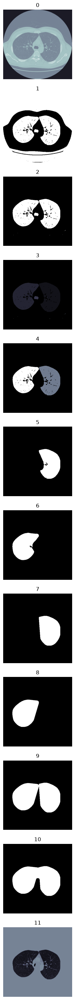

In [10]:
from matplotlib import pyplot as plt
tmp_2d_img = get_segmented_lungs(img2[200,:,:], True)

C:\Users\Stephanie ASSAMOI\AppData\Local\Temp\ipykernel_15320\2850321879.py:105: FutureWarning: `binary_closing` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.closing` instead.
  binary = binary_closing(binary, selem)
C:\Users\Stephanie ASSAMOI\AppData\Local\Temp\ipykernel_15320\2850321879.py:105: FutureWarning: `binary_closing` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.closing` instead.
  binary = binary_closing(binary, selem)
C:\Users\Stephanie ASSAMOI\AppData\Local\Temp\ipykernel_15320\2850321879.py:105: FutureWarning: `binary_closing` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.closing` instead.
  binary = binary_closing(binary, selem)
C:\Users\Stephanie ASSAMOI\AppData\Local\Temp\ipykernel_15320\2850321879.py:105: FutureWarning: `binary_closing` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morpho

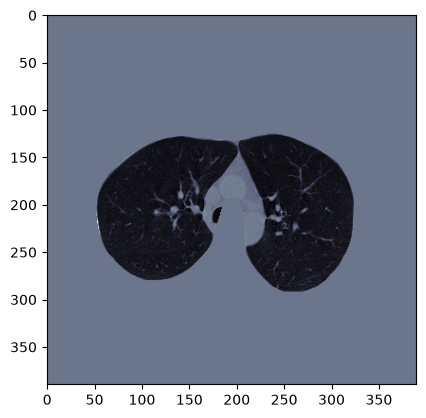

In [ ]:
img3 = np.asarray([get_segmented_lungs(im) for im in img2])

from matplotlib import pyplot as plt
plt.imshow(img3[201,:,:], cmap=plt.cm.bone)
plt.show()

In [13]:
def normalize(image):
        MIN_BOUND = -1200
        MAX_BOUND = 600.
        image2 = (image - MIN_BOUND) / (MAX_BOUND - MIN_BOUND)
        image2[image2 > 1] = 1.
        image2[image2 < 0] = 0.
        image2 *= 255.
        return image2



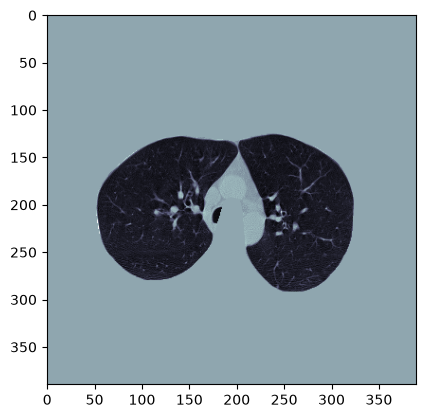

In [14]:
img4 = normalize(img3)
plt.imshow(img4[201,:,:], cmap=plt.cm.bone)
plt.show()

In [15]:
def zero_center(image):
    PIXEL_MEAN = 0.25 * 256
    image2 = image - PIXEL_MEAN
    return image2

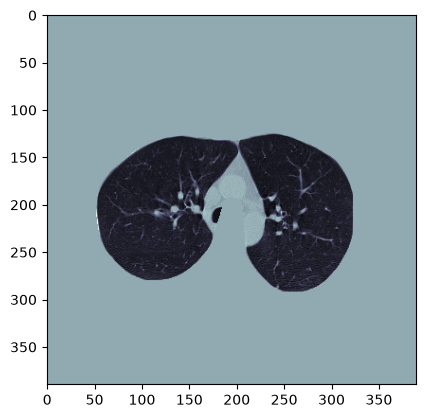

In [16]:
img5 = zero_center(img4)
plt.imshow(img5[200,:,:], cmap=plt.cm.bone)
plt.show()

In [17]:
import os
import glob
import numpy as np
import scipy.ndimage as ndi
import SimpleITK as sitk
from skimage import measure, morphology
from skimage.morphology import disk, convex_hull_image, binary_closing
from skimage.filters import roberts
from skimage.segmentation import clear_border
from collections import defaultdict

In [18]:
def ensure_dir(path):
    os.makedirs(path, exist_ok=True)

BASE_PROC = "../data/preprocessing"
PROC_TRAIN = os.path.join(BASE_PROC, "processed/train")
META_TRAIN = os.path.join(BASE_PROC, "metadata/train")

for subset in ["subset0", "subset1", "subset2"]:
    ensure_dir(os.path.join(PROC_TRAIN, subset))
    ensure_dir(os.path.join(META_TRAIN, subset))

In [19]:
def preprocess_patient(mhd_path, out_npy_path, meta_path):
    # 1. Load
    img, origin, spacing = load_itk(mhd_path)

    # 2. Resample
    img, new_spacing = resample(img, spacing)

    # 3. Lung segmentation
    img = np.asarray([get_segmented_lungs(im) for im in img])

    # 4. Normalize
    img = normalize(img)

    # 5. Zero center
    img = zero_center(img)

    # 6. Save volume
    np.save(out_npy_path, img.astype(np.float32))

    # 7. Save metadata
    np.save(meta_path, {
        "origin": origin,
        "spacing": new_spacing,
        "shape": img.shape
    })

In [20]:
file_list = (
    glob.glob("../data/preprocessing/train/subset0/*.mhd")
    + glob.glob("../data/preprocessing/train/subset1/*.mhd")
    + glob.glob("../data/preprocessing/train/subset2/*.mhd")
)

for mhd_path in file_list:
    subset = os.path.basename(os.path.dirname(mhd_path))
    patient_id = os.path.basename(mhd_path).replace(".mhd", "")

    out_npy = os.path.join(PROC_TRAIN, subset, f"{patient_id}.npy")
    meta_npy = os.path.join(META_TRAIN, subset, patient_id)

    # Évite de refaire un patient déjà traité
    if os.path.exists(out_npy):
        print(f"⏩ Déjà traité : {patient_id}")
        continue

    try:
        preprocess_patient(mhd_path, out_npy, meta_npy)
        print(f"✅ Traité : {patient_id}")
    except Exception as e:
        print(f"❌ Erreur sur {patient_id} : {e}")

C:\Users\Stephanie ASSAMOI\AppData\Local\Temp\ipykernel_15320\2850321879.py:105: FutureWarning: `binary_closing` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.closing` instead.
  binary = binary_closing(binary, selem)
C:\Users\Stephanie ASSAMOI\AppData\Local\Temp\ipykernel_15320\2850321879.py:105: FutureWarning: `binary_closing` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.closing` instead.
  binary = binary_closing(binary, selem)
C:\Users\Stephanie ASSAMOI\AppData\Local\Temp\ipykernel_15320\2850321879.py:105: FutureWarning: `binary_closing` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.closing` instead.
  binary = binary_closing(binary, selem)
C:\Users\Stephanie ASSAMOI\AppData\Local\Temp\ipykernel_15320\2850321879.py:105: FutureWarning: `binary_closing` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morpho

✅ Traité : 1.3.6.1.4.1.14519.5.2.1.6279.6001.105756658031515062000744821260


C:\Users\Stephanie ASSAMOI\AppData\Local\Temp\ipykernel_15320\2850321879.py:105: FutureWarning: `binary_closing` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.closing` instead.
  binary = binary_closing(binary, selem)
C:\Users\Stephanie ASSAMOI\AppData\Local\Temp\ipykernel_15320\2850321879.py:105: FutureWarning: `binary_closing` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.closing` instead.
  binary = binary_closing(binary, selem)
C:\Users\Stephanie ASSAMOI\AppData\Local\Temp\ipykernel_15320\2850321879.py:105: FutureWarning: `binary_closing` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.closing` instead.
  binary = binary_closing(binary, selem)
C:\Users\Stephanie ASSAMOI\AppData\Local\Temp\ipykernel_15320\2850321879.py:105: FutureWarning: `binary_closing` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morpho

✅ Traité : 1.3.6.1.4.1.14519.5.2.1.6279.6001.108197895896446896160048741492


C:\Users\Stephanie ASSAMOI\AppData\Local\Temp\ipykernel_15320\2850321879.py:105: FutureWarning: `binary_closing` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.closing` instead.
  binary = binary_closing(binary, selem)
C:\Users\Stephanie ASSAMOI\AppData\Local\Temp\ipykernel_15320\2850321879.py:105: FutureWarning: `binary_closing` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.closing` instead.
  binary = binary_closing(binary, selem)
C:\Users\Stephanie ASSAMOI\AppData\Local\Temp\ipykernel_15320\2850321879.py:105: FutureWarning: `binary_closing` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.closing` instead.
  binary = binary_closing(binary, selem)
C:\Users\Stephanie ASSAMOI\AppData\Local\Temp\ipykernel_15320\2850321879.py:105: FutureWarning: `binary_closing` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morpho

✅ Traité : 1.3.6.1.4.1.14519.5.2.1.6279.6001.109002525524522225658609808059


... (524 outputs left out)

C:\Users\Stephanie ASSAMOI\AppData\Local\Temp\ipykernel_15320\2850321879.py:105: FutureWarning: `binary_closing` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.closing` instead.
  binary = binary_closing(binary, selem)
C:\Users\Stephanie ASSAMOI\AppData\Local\Temp\ipykernel_15320\2850321879.py:105: FutureWarning: `binary_closing` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.closing` instead.
  binary = binary_closing(binary, selem)
C:\Users\Stephanie ASSAMOI\AppData\Local\Temp\ipykernel_15320\2850321879.py:105: FutureWarning: `binary_closing` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.closing` instead.
  binary = binary_closing(binary, selem)
C:\Users\Stephanie ASSAMOI\AppData\Local\Temp\ipykernel_15320\2850321879.py:105: FutureWarning: `binary_closing` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morpho

✅ Traité : 1.3.6.1.4.1.14519.5.2.1.6279.6001.943403138251347598519939390311


C:\Users\Stephanie ASSAMOI\AppData\Local\Temp\ipykernel_15320\2850321879.py:105: FutureWarning: `binary_closing` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.closing` instead.
  binary = binary_closing(binary, selem)
C:\Users\Stephanie ASSAMOI\AppData\Local\Temp\ipykernel_15320\2850321879.py:105: FutureWarning: `binary_closing` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.closing` instead.
  binary = binary_closing(binary, selem)
C:\Users\Stephanie ASSAMOI\AppData\Local\Temp\ipykernel_15320\2850321879.py:105: FutureWarning: `binary_closing` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.closing` instead.
  binary = binary_closing(binary, selem)
C:\Users\Stephanie ASSAMOI\AppData\Local\Temp\ipykernel_15320\2850321879.py:105: FutureWarning: `binary_closing` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morpho

✅ Traité : 1.3.6.1.4.1.14519.5.2.1.6279.6001.964952370561266624992539111877


(302, 390, 390) float32
-57.625 191.0 88.85556


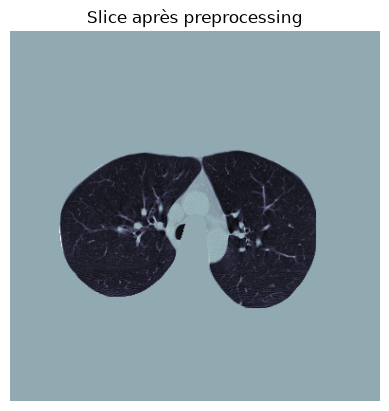

(308, 250, 250) float32
-53.516666 191.0 78.469215


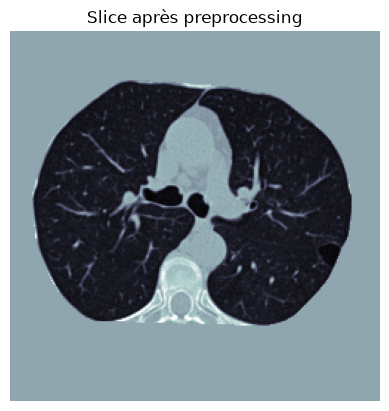

In [27]:
sample = np.load("../data/preprocessing/processed/train/subset0/1.3.6.1.4.1.14519.5.2.1.6279.6001.105756658031515062000744821260.npy")
print(sample.shape, sample.dtype)
print(sample.min(), sample.max(), sample.mean())
plt.imshow(sample[200], cmap="bone")
plt.title("Slice après preprocessing")
plt.axis("off")
plt.show()

sample = np.load("../data/preprocessing/processed/train/subset1/1.3.6.1.4.1.14519.5.2.1.6279.6001.100684836163890911914061745866.npy")
print(sample.shape, sample.dtype)
print(sample.min(), sample.max(), sample.mean())
plt.imshow(sample[200], cmap="bone")
plt.title("Slice après preprocessing")
plt.axis("off")
plt.show()

In [1]:
import os
import glob
import numpy as np
import pandas as pd
import SimpleITK as sitk
 
# ============================================================
# EXTRACTION DE PATCHS À PARTIR DES VOLUMES DÉJÀ PRÉTRAITÉS
# ============================================================
# On ne relance PAS le preprocessing (resample, segmentation,
# normalize, zero_center) car les .npy existants sont déjà bons.
# On a seulement besoin de recharger le .mhd original pour la
# conversion monde -> voxel (origin/spacing/direction), ce qui est
# rapide (pas de traitement d'image, juste lecture des métadonnées
# + du volume brut pour la transformation ITK).
 
BASE_PROC = "../data/preprocessing"
PROC_TRAIN = os.path.join(BASE_PROC, "processed/train")
META_TRAIN = os.path.join(BASE_PROC, "metadata/train")
PATCH_DIR = os.path.join(BASE_PROC, "patches")
os.makedirs(PATCH_DIR, exist_ok=True)
 
PATCH_SIZE = 32

In [2]:
def world_to_voxel_itk(itkimage, world_coord):
    """
    Convertit une coordonnée monde (x, y, z) en mm vers une coordonnée
    voxel (z, y, x), en utilisant la transformation complète de SimpleITK
    (origin + spacing + direction) sur un objet image déjà chargé.
    """
    voxel_xyz = itkimage.TransformPhysicalPointToContinuousIndex(
        [float(world_coord[0]), float(world_coord[1]), float(world_coord[2])]
    )
    return np.array(voxel_xyz)[::-1]  # (x,y,z) -> (z,y,x)

In [3]:
def get_original_spacing(itkimage):
    """Spacing d'origine (ordre z,y,x) à partir d'un itkimage déjà chargé."""
    return np.array(list(reversed(itkimage.GetSpacing())))

In [4]:
def extract_patch(volume, center_zyx, patch_size=32):
    """Identique à avant : extrait un cube centré sur center_zyx, avec padding aux bords."""
    z, y, x = [int(round(c)) for c in center_zyx]
    half = patch_size // 2
 
    z_min, z_max = z - half, z + half
    y_min, y_max = y - half, y + half
    x_min, x_max = x - half, x + half
 
    pad_z_before = max(0, -z_min)
    pad_y_before = max(0, -y_min)
    pad_x_before = max(0, -x_min)
 
    pad_z_after = max(0, z_max - volume.shape[0])
    pad_y_after = max(0, y_max - volume.shape[1])
    pad_x_after = max(0, x_max - volume.shape[2])
 
    z_min_c, z_max_c = max(0, z_min), min(volume.shape[0], z_max)
    y_min_c, y_max_c = max(0, y_min), min(volume.shape[1], y_max)
    x_min_c, x_max_c = max(0, x_min), min(volume.shape[2], x_max)
 
    cropped = volume[z_min_c:z_max_c, y_min_c:y_max_c, x_min_c:x_max_c]
 
    patch = np.pad(
        cropped,
        ((pad_z_before, pad_z_after), (pad_y_before, pad_y_after), (pad_x_before, pad_x_after)),
        mode='constant',
        constant_values=0
    )
    return patch
 

In [6]:
def extract_patches_for_patient(mhd_path, candidates_df, patch_size=PATCH_SIZE):
    """
    Pour un patient déjà prétraité :
    1. Retrouve son .npy prétraité et ses métadonnées déjà sauvegardées.
    2. Convertit les coordonnées de ses candidats (monde -> voxel original).
    3. Repositionne ces coordonnées dans le référentiel du volume rééchantillonné
       en utilisant le spacing d'origine et le spacing sauvegardé (post-resample).
    4. Extrait et sauvegarde un patch par candidat.
    """
    patient_id = os.path.basename(mhd_path).replace(".mhd", "")
    subset = os.path.basename(os.path.dirname(mhd_path))
 
    npy_path = os.path.join(PROC_TRAIN, subset, f"{patient_id}.npy")
    meta_path = os.path.join(META_TRAIN, subset, f"{patient_id}.npy")
 
    if not os.path.exists(npy_path):
        print(f"⏭️  Pas de volume prétraité pour {patient_id}, on saute.")
        return 0
 
    patient_candidates = candidates_df[candidates_df["seriesuid"] == patient_id]
    if len(patient_candidates) == 0:
        return 0
 
    # Volume déjà prétraité (segmentation + normalize + zero_center faits)
    img_final = np.load(npy_path)
 
    # Métadonnées déjà sauvegardées lors du premier preprocessing
    meta = np.load(meta_path, allow_pickle=True).item()
    new_spacing = np.array(meta["spacing"])  # spacing APRÈS resample, déjà sauvegardé
 
    # On charge le .mhd UNE SEULE FOIS pour ce patient (pas par candidat),
    # pour la conversion de coordonnées et le spacing d'origine.
    itkimage = sitk.ReadImage(mhd_path)
    original_spacing = get_original_spacing(itkimage)
    real_resize_factor = original_spacing / new_spacing
 
    # Sous-dossier par subset, pour respecter le split officiel LUNA16
    # (nécessaire pour la validation croisée par subset, sans fuite de
    # données entre patients d'un même patient/subset).
    out_dir = os.path.join(PATCH_DIR, subset)
    os.makedirs(out_dir, exist_ok=True)
 
    n_saved = 0
    for idx, row in patient_candidates.iterrows():
        world_coord = (row["coordX"], row["coordY"], row["coordZ"])
        voxel_orig = world_to_voxel_itk(itkimage, world_coord)
        voxel_resampled = voxel_orig * real_resize_factor
 
        patch = extract_patch(img_final, voxel_resampled, patch_size)
        label_val = int(row["class"])
 
        out_name = f"{patient_id}_{idx}_class{label_val}.npy"
        np.save(os.path.join(out_dir, out_name), patch.astype(np.float32))
        n_saved += 1
 
    return n_saved
 
 
if __name__ == "__main__":
    candidates = pd.read_csv("../data/candidates_V2/candidates_V2.csv")
 
    file_list = (
        glob.glob("../data/preprocessing/train/subset0/*.mhd")
        + glob.glob("../data/preprocessing/train/subset1/*.mhd")
        + glob.glob("../data/preprocessing/train/subset2/*.mhd")
    )
 
    total_patches = 0
    for mhd_path in file_list:
        patient_id = os.path.basename(mhd_path).replace(".mhd", "")
        try:
            n = extract_patches_for_patient(mhd_path, candidates)
            if n > 0:
                print(f"✅ {patient_id} : {n} patchs extraits")
            total_patches += n
        except Exception as e:
            print(f"❌ Erreur sur {patient_id} : {e}")
 
    print(f"\nTotal : {total_patches} patchs extraits dans {PATCH_DIR} (organisés par subset)")
 

✅ 1.3.6.1.4.1.14519.5.2.1.6279.6001.105756658031515062000744821260 : 707 patchs extraits
✅ 1.3.6.1.4.1.14519.5.2.1.6279.6001.108197895896446896160048741492 : 1291 patchs extraits
✅ 1.3.6.1.4.1.14519.5.2.1.6279.6001.109002525524522225658609808059 : 804 patchs extraits
✅ 1.3.6.1.4.1.14519.5.2.1.6279.6001.111172165674661221381920536987 : 730 patchs extraits
✅ 1.3.6.1.4.1.14519.5.2.1.6279.6001.122763913896761494371822656720 : 821 patchs extraits
✅ 1.3.6.1.4.1.14519.5.2.1.6279.6001.124154461048929153767743874565 : 1333 patchs extraits
✅ 1.3.6.1.4.1.14519.5.2.1.6279.6001.126121460017257137098781143514 : 615 patchs extraits
✅ 1.3.6.1.4.1.14519.5.2.1.6279.6001.126264578931778258890371755354 : 1129 patchs extraits
✅ 1.3.6.1.4.1.14519.5.2.1.6279.6001.128023902651233986592378348912 : 1083 patchs extraits
✅ 1.3.6.1.4.1.14519.5.2.1.6279.6001.129055977637338639741695800950 : 961 patchs extraits
✅ 1.3.6.1.4.1.14519.5.2.1.6279.6001.130438550890816550994739120843 : 1262 patchs extraits
✅ 1.3.6.1.4.1.14

Patient tested : 1.3.6.1.4.1.14519.5.2.1.6279.6001.100621383016233746780170740405
File found : ../data/preprocessing/train/subset2\1.3.6.1.4.1.14519.5.2.1.6279.6001.100621383016233746780170740405.mhd
Number of candidates : 854
Voxel calculated (z,y,x) : (248, 157, 122)


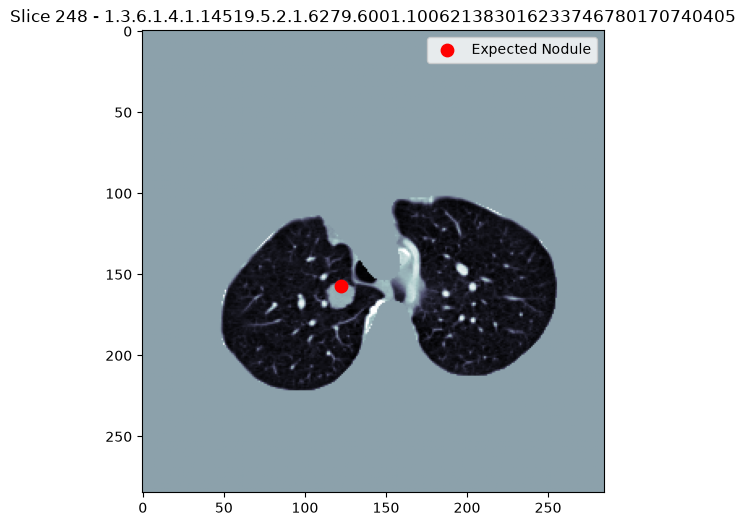

In [ ]:
import matplotlib.pyplot as plt

# IDs des patients réellement présents dans tes 3 subsets traités
available_ids = set(os.path.basename(f).replace(".mhd", "") for f in file_list)

# Parmi les vrais nodules, on ne garde que ceux dont le patient est disponible
real_nodules_available = candidates[
    (candidates["class"] == 1) & (candidates["seriesuid"].isin(available_ids))
]

test_patient_id = real_nodules_available["seriesuid"].iloc[3]   # un autre patient
test_mhd_path = None
for f in file_list:
    if test_patient_id in f:
        test_mhd_path = f
        break

print(f"Patient tested : {test_patient_id}")
print(f"File found : {test_mhd_path}")

subset = os.path.basename(os.path.dirname(test_mhd_path))
npy_path = os.path.join(PROC_TRAIN, subset, f"{test_patient_id}.npy")
meta_path = os.path.join(META_TRAIN, subset, f"{test_patient_id}.npy")

img_final = np.load(npy_path)
meta = np.load(meta_path, allow_pickle=True).item()
new_spacing = np.array(meta["spacing"])

itkimage = sitk.ReadImage(test_mhd_path)
original_spacing = get_original_spacing(itkimage)
real_resize_factor = original_spacing / new_spacing

patient_candidates = candidates[candidates["seriesuid"] == test_patient_id]

print(f"Number of candidates : {len(patient_candidates)}")

row = patient_candidates[patient_candidates["class"] == 1].iloc[0]
world_coord = (row["coordX"], row["coordY"], row["coordZ"])

voxel_orig = world_to_voxel_itk(itkimage, world_coord)
voxel_resampled = voxel_orig * real_resize_factor
z, y, x = [int(round(c)) for c in voxel_resampled]

print(f"Voxel calculated (z,y,x) : {z, y, x}")

plt.figure(figsize=(6,6))
plt.imshow(img_final[z], cmap="bone")
plt.scatter(x, y, color="red", s=80, label="Expected Nodule")
plt.title(f"Slice {z} - {test_patient_id}")
plt.legend()
plt.show()